# Manual segmentation

To avoid segementing every slice (because it is very tedious), we can segment one every 3 slice and then use registration to fill in the gaps. 
We use the method of Jaume to do so.

Idea: Take two consequtive segmented slices. There might be two or three none segmented slices inbetween. Let n be the numeber of slices. We register slice 1 to slice 2, slice 2 to slice 3 until n. Classical methods then use the transformation from slice to slice to reconstruct the segementation. In our case we will also register from 1 to n, from n to n-1 ... and the transformation to go from 1 to i will be a weighted average between the forward path (classic path) and the backward path (the additional path). This metigates the error accumalated from one slice to another. 

## 📦 Imports

In [1]:
import nibabel as nib
import mindmap as mm
import numpy as np
import ants
from pathlib import Path

## 🧠 Data

In [2]:
# configuration
env    = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(env["MM_DIR"])
ds_dir = Path(env["DS_DIR"])

sub = "sub-pat09"

# data
data    = mm.io.read_dataset(sub, "parc")
volume  = ds_dir/"derivatives"/"cmp-v3.0.0-beta-RC1"/sub/"ses-preop"/"anat"/f"{sub}_ses-preop_res-cmp_T1w.nii.gz"
man_seg = mm_dir/sub/"resec"/f"{sub}_man-seg.nii.gz"

# features
gm_mask = data["parc"].create_mask()
volume  = ants.image_read(str(volume))
man_seg = ants.image_read(str(man_seg))

🌟 **Visualize MRIs**

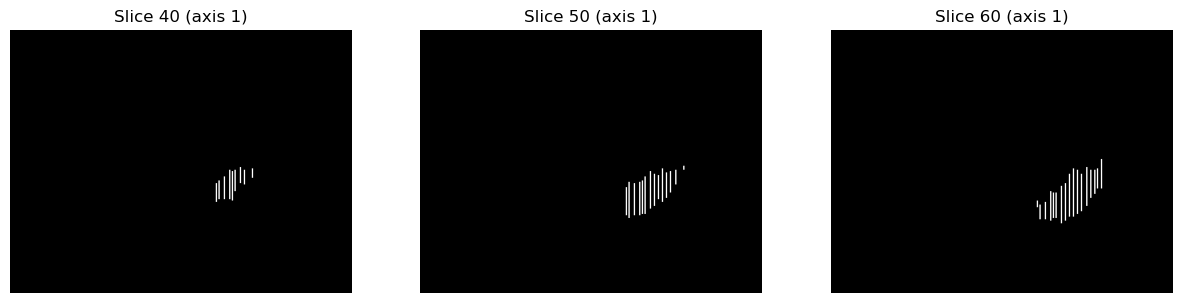

In [3]:
s = [40,50,60]
mm.viz.show_slices(man_seg.numpy(), s, axis=1)

## Reconstruct Segmentation
⚙️ <font color=green>**Fill layers inbetween using ANTs registration**</font>

In [4]:
# reconstruct segmentation
def recon_segmentation(volume:nib.Nifti1Image, segmentation:nib.Nifti1Image):
    """
    Reconstruct segmentation using volume registration. Volume and segmentation need to be 
    registered to eachother.

    Parameters:
    ----------
    volume: nib.nifti1Image | ants.Image
        Volume in which the segmentation exists.

    segmentation: mm.Parcellation
        Partial segmentation.

    axis: int
        Axis along which the segmentation was performed.

    Returns:
    -------
    segmentation: mm.Parcellation
        Reconstructed segmentation.
    """

    # find segmented slices
    tmp    = np.sum(segmentation.numpy(), axis=(0,1))
    slices = np.where(tmp>0)[0]
    seg    = segmentation.clone()

    for i in range(slices.shape[0]-1):
        start = slices[i]
        end   = slices[i+1]
        if end-start < 2: continue

        # fill slices
        registrations = []
        for j in range(start, end-1):
            fixed  = ants.slice_image(volume, axis=2, idx=j+1)
            moving = ants.slice_image(volume, axis=2, idx=j)
            registrations.append(ants.registration(fixed, moving, "SyN", write_composition_transform=True)["fwdtransforms"])

            moving = ants.slice_image(seg, axis=2, idx=j)
            transformlist = [r for reg in registrations for r in reg]
            new_slice = ants.apply_transforms(fixed, moving, transformlist=transformlist, interpolator="genericLabel")
            seg[:,:,j+1] = new_slice.numpy()

    return seg

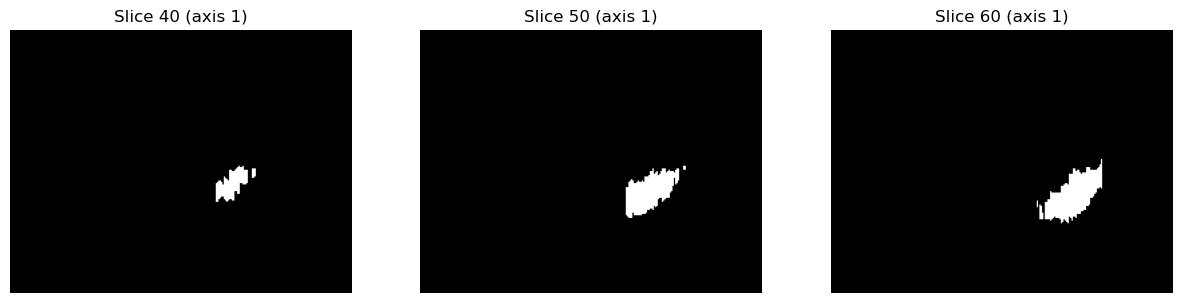

In [5]:
seg = recon_segmentation(volume, man_seg)
mm.viz.show_slices(seg.numpy(), s, axis=1)

In [6]:
print(f"Saving resected area for subject: {sub}")
seg.to_file(str(mm_dir/sub/"resec"/f"{sub}_man-recon-TEST-seg.nii.gz"))

Saving resected area for subject: sub-pat09


⚙️ <font color=green>**Apply GM mask**</font>

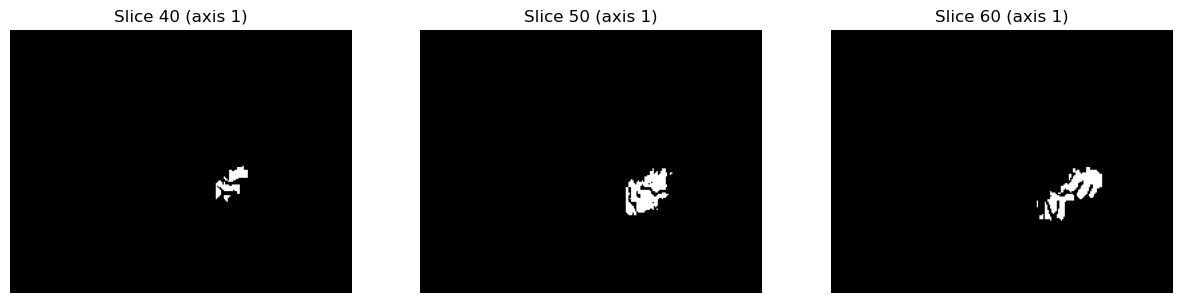

In [24]:
seg[:,:,:] = seg.numpy()*gm_mask.get_fdata()
mm.viz.show_slices(seg.numpy(), s, axis=1)

## 💾 Save Resection mask

In [9]:
print(f"Saving resected area for subject: {sub}")
seg.to_file(str(mm_dir/sub/"resec"/f"{sub}_man-recon-seg.nii.gz"))

Saving resected area for subject: sub-pat27


# Compute forward and backward registration

In [ ]:
# Retrieve idx of segmented slices
tmp = np.sum(orig_seg.numpy(), axis=(0,1))
slices = np.where(tmp>0)[0]

for i in range(len(slices)-1):
    n = slices[i+1]-slices[i]          # number of registrations -1 (registration from start to end is not counted)
    
    if n<2:
        continue    # n<2 means no inbetween slices 
    
    else:
        fixed  = ants.slice_image(semi_mask, 2, slices[i])
        moving = ants.slice_image(semi_mask, 2, slices[i+1])
        registrations = [ants.registration(fixed, moving, "SyN", write_composite_transform=True)]

        for s in range(n):
            fixed  = ants.slice_image(volume, 2, slices[i]+s)
            moving = ants.slice_image(volume, 2, slices[i]+s+1)
            registrations.append(ants.registration(fixed, moving, "SyN", write_composite_transform=True))
    
        start = ants.slice_image(volume, axis=2, idx=slices[i])
        end   = ants.slice_image(volume, axis=2, idx=slices[i+1])
        registrations.append(ants.registration(start, end, "SyN", write_composite_transform=True))

        # register segmentation inbetween manualy segmented slices
        for j in range(n-1):
            forward  = [registrations[k]["fwdtransforms"] for k in range(j+1)]
            backward = [registrations[n-k]["invtransforms"] for k in range(n-j)]

            fixed  = ants.slice_image(volume, 2, slices[i]+j+1)
            moving = ants.slice_image(semi_mask, 2, slices[i]+j)
            forward_img  = ants.apply_transforms(fixed, moving, transformlist=forward, interpolator="genericLabel")
            backward_img = ants.apply_transforms(fixed, moving, transformlist=backward, interpolator="genericLabel")
            
            #semi_mask[:,:,slices[i]+j+1] = forward_img.numpy() 
            semi_mask[:,:,slices[i+j+1]] = ((n-j-1)*forward_img.numpy() + (j+1)*backward_img.numpy())/n

In [4]:
# Retrieve idx of segmented slices
tmp = np.sum(semi_mask.numpy(), axis=(0,1))
slices = np.where(tmp>0)[0]

for i in range(len(slices)-1):
    n = slices[i+1]-slices[i]          # number of registrations -1 (registration from start to end is not counted)
    
    if n<2:
        continue    # n<2 means no inbetween slices 
    
    else:
        registrations = []

        for s in range(n):
            fixed  = ants.slice_image(volume, 2, slices[i]+s)
            moving = ants.slice_image(volume, 2, slices[i]+s+1)
            registrations.append(ants.registration(fixed, moving, "SyN", write_composite_transform=True))
    
        start = ants.slice_image(volume, axis=2, idx=slices[i])
        end   = ants.slice_image(volume, axis=2, idx=slices[i+1])
        registrations.append(ants.registration(start, end, "SyN", write_composite_transform=True))

        # register segmentation inbetween manualy segmented slices
        for j in range(n-1):
            forward  = [registrations[k]["fwdtransforms"] for k in range(j+1)]
            backward = [registrations[n-k]["invtransforms"] for k in range(n-j)]

            fixed  = ants.slice_image(volume, 2, slices[i]+j+1)
            moving = ants.slice_image(semi_mask, 2, slices[i]+j)
            forward_img  = ants.apply_transforms(fixed, moving, transformlist=forward, interpolator="genericLabel")
            backward_img = ants.apply_transforms(fixed, moving, transformlist=backward, interpolator="genericLabel")
            
            #semi_mask[:,:,slices[i]+j+1] = forward_img.numpy() 
            semi_mask[:,:,slices[i+j+1]] = ((n-j-1)*forward_img.numpy() + (j+1)*backward_img.numpy())/n

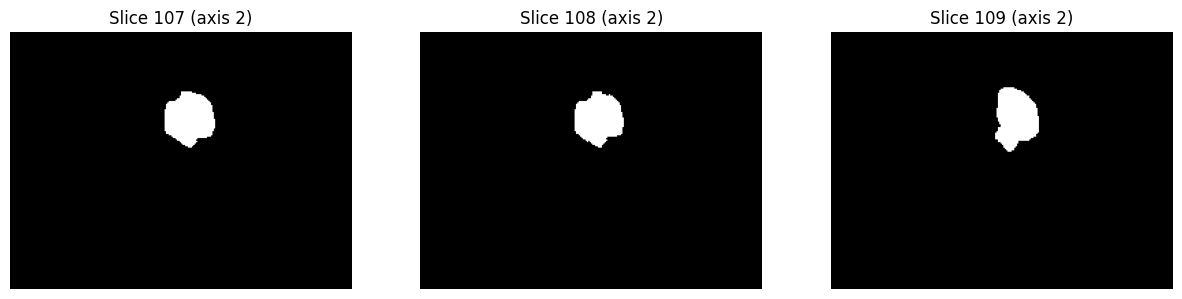

In [5]:
mm.viz.show_slices(semi_mask.numpy(), [107,108,109], axis=2)

In [6]:
semi_mask.to_file("test.nii.gz")

In [ ]:
# reconstruct segmentation
def recon_segmentation(volume:nib.Nifti1Image, segmentation:nib.Nifti1Image, axis):
    """
    Reconstruct segmentation using volume registration. Volume and segmentation need to be 
    registered to eachother.

    Parameters:
    ----------
    volume: nib.nifti1Image | ants.Image
        Volume in which the segmentation exists.

    segmentation: mm.Parcellation
        Partial segmentation.

    axis: int
        Axis along which the segmentation was performed.

    Returns:
    -------
    segmentation: mm.Parcellation
        Reconstructed segmentation.
    """

    # find segmented slices
    tmp = np.sum(segmentation.get_fdata(), axis=axis)
    slices = np.where(tmp>0)

    for i in slices.shape[0]-1:
        start = slices[i]
        end = slices[i+1]

        forward = []
        backward = [ants.registration(volume[start], volume[end], "SyN")]

        s = start
        while start+s < end:

            # forward correction fields
            forward.append(ants.registration(volume[start+s], volume[start+s+1], "SyN"))

            # backward correction fields
            backward.append(ants.registration(volume[end-s], volume[end-s-1], "SyN"))

            s += 1

        # register inbetween slices
        #for i in range(s):
        #    f = np.sum(forward[:i])
        #    b = np.sum(backward[:i-1])

        #    volume[start+i] += ((s-i)*f + (i)*b)/s

        return


In [1]:
import ants

template = "/home/admin/work/data/atlas/mni_icbm152_nlin_asym_09c_nifti/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii"
mri = "/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cmp-v3.0.0-beta-RC1/sub-pat10/ses-preop/anat/sub-pat10_ses-preop_res-cmp_T1w.nii.gz"

template = ants.image_read(template)
mri = ants.image_read(mri)

out = ants.registration(mri, template, "SyN")

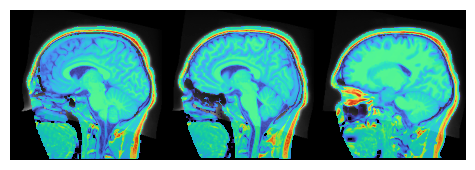

In [4]:
ants.plot(out["warpedmovout"], mri, slices=[90, 100, 110], axis=0)

In [6]:
out["warpedmovout"].to_file("test.nii.gz")